# 02 – Backtest de la stratégie momentum

On simule la stratégie **momentum 12-1, top 20 %, rebalancement mensuel** (net de coûts de 10 pb) et on la compare à l'achat-conservation équipondéré.

Prérequis : `python src/ingest.py` et le module `src/backtest.py`.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import drawdown, load_prices
from backtest import backtest_momentum, equity_curve, performance_table

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

STRAT, BENCH = '#2563eb', '#9ca3af'  # bleu = stratégie, gris = marché

## 1. Lancer le backtest

In [3]:
prices = load_prices(ROOT / 'data' / 'market.duckdb')
bt = backtest_momentum(prices, frac=0.2, cost_bps=10)
print(f'{len(bt)} mois, du {bt.index[0]:%m/%Y} au {bt.index[-1]:%m/%Y}')
bt.tail()

130 mois, du 02/2016 au 11/2026


,strategy,benchmark
date,,
2026-07-31,-0.075,0.025
2026-08-31,-0.004,0.039
2026-09-30,0.030,-0.029
2026-10-31,-0.028,0.031
2026-11-30,-0.071,-0.014


## 2. Courbe de capital

Valeur d'1 $ investi au départ. Échelle log : une même pente = un même rendement en %.

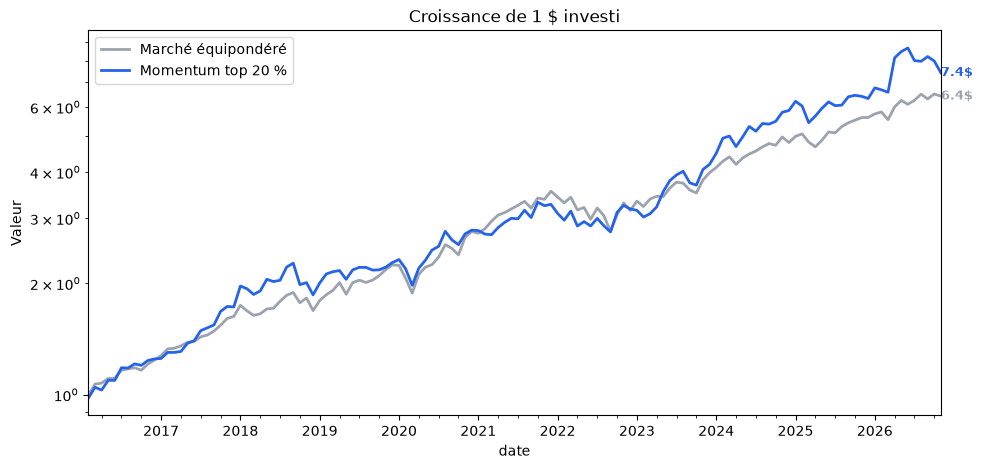

In [6]:
eq = equity_curve(bt)
ax = eq['benchmark'].plot(color=BENCH, linewidth=2, label='Marché équipondéré')
eq['strategy'].plot(ax=ax, color=STRAT, linewidth=2, label='Momentum top 20 %')
for col, color in [('strategy', STRAT), ('benchmark', BENCH)]:
    ax.annotate(f"{eq[col].iloc[-1]:.1f}$", (eq.index[-1], eq[col].iloc[-1]),
                color=color, fontsize=9, fontweight='bold', va='center')
ax.set(title='Croissance de 1 $ investi', ylabel='Valeur', yscale='log')
ax.legend();

**Lecture.** **1 \$** investi au départ devient **7,4 \$** avec le momentum contre **6,4 \$** pour le marché : la stratégie compose un peu plus vite sur la période. En échelle log, la courbe bleue reste globalement au-dessus de la grise avec une pente comparable — l'avantage se construit surtout lors des phases de rebond, pas d'un seul coup.


## 3. Drawdowns comparés

Perte depuis le plus haut atteint, à chaque mois. Plus la zone est creuse, plus l'investisseur a souffert.

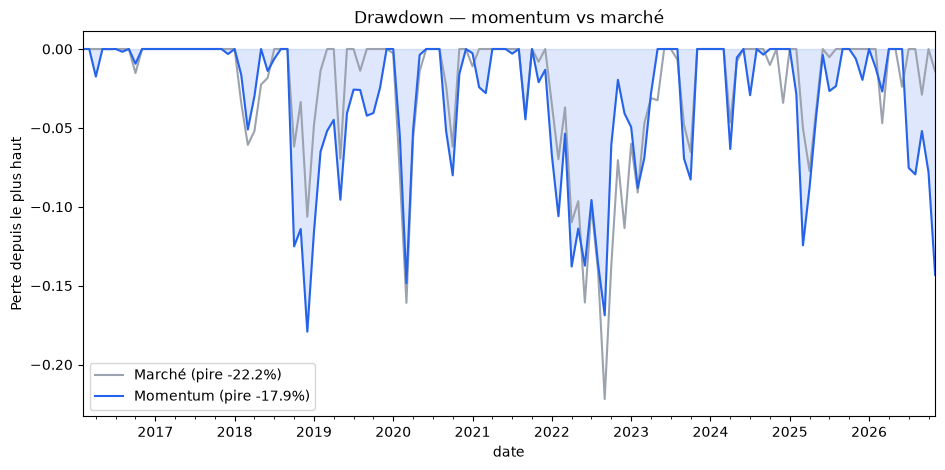

In [4]:
dd_s, dd_b = drawdown(bt['strategy']), drawdown(bt['benchmark'])
ax = dd_b.plot(color=BENCH, linewidth=1.5, label=f'Marché (pire {dd_b.min():.1%})')
dd_s.plot(ax=ax, color=STRAT, linewidth=1.5, label=f'Momentum (pire {dd_s.min():.1%})')
ax.fill_between(dd_s.index, dd_s, 0, color=STRAT, alpha=0.15)
ax.set(title='Drawdown — momentum vs marché', ylabel='Perte depuis le plus haut')
ax.legend();

**Lecture.** Le pire creux du momentum est **-17,9 %**, contre **-22,2 %** pour le marché : à chaque épisode de stress, la stratégie descend moins bas et remonte plus vite. C'est sa principale qualité défensive — elle sort des titres qui décrochent avant qu'ils ne pèsent trop.

## 4. Tableau de performance

Rendement annualisé, volatilité, Sharpe et pire drawdown, net de coûts.

In [5]:
performance_table(bt)

,rendement_annuel,volatilite_annuelle,sharpe,max_drawdown
strategy,0.203,0.183,1.108,-0.179
benchmark,0.187,0.144,1.271,-0.222


**Lecture.** La stratégie gagne plus (**20,3 %** vs 18,7 %) et chute moins (**-17,9 %** vs -22,2 %), mais au prix d'une volatilité plus forte (**18,3 %** vs 14,4 %). Résultat : son **Sharpe est plus bas** (1,11 vs 1,27). Autrement dit, plus de rendement brut mais moins bien rémunéré par unité de risque — c'est l'arbitrage central à surveiller.

## 5. Rendement par année civile

Quand la stratégie bat-elle le marché, et quand sous-performe-t-elle ?

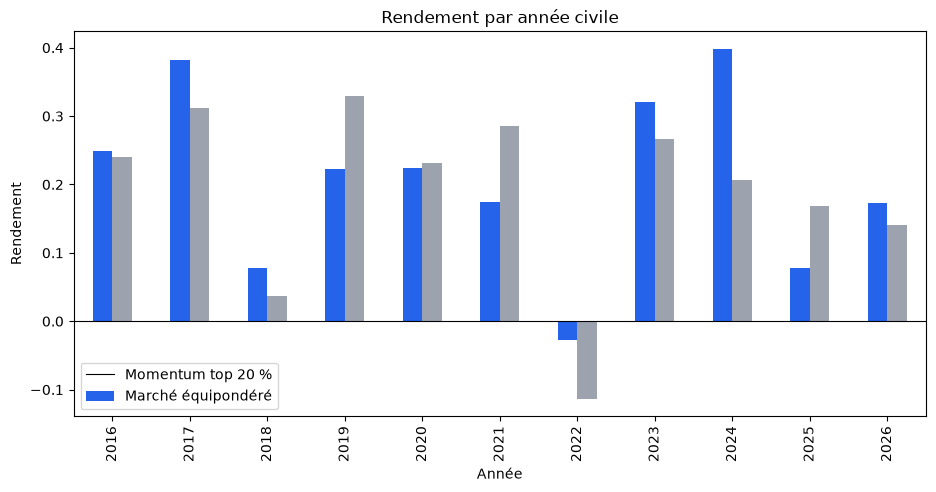

In [6]:
annual = bt.groupby(bt.index.year).apply(lambda r: (1 + r).prod() - 1)
ax = annual.plot.bar(color=[STRAT, BENCH])
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Rendement par année civile', ylabel='Rendement', xlabel='Année')
ax.legend(['Momentum top 20 %', 'Marché équipondéré']);

**Lecture.** Le momentum bat le marché **7 années sur 11**. Son meilleur atout se voit en **2022** : -2,8 % contre -11,4 % pour le marché, soit une chute bien amortie. En revanche il reste en retrait lors des marchés très porteurs et grégaires (**2019, 2021, 2025**), où suivre la tendance n'apporte pas d'avantage. La surperformance n'est donc ni régulière ni garantie : elle dépend du régime de marché.

## À retenir

- La stratégie bat le marché en **rendement absolu** et limite mieux les **drawdowns**, mais pour une **volatilité plus élevée** → Sharpe à surveiller.
- Résultat **en échantillon**, un seul jeu de paramètres, sur des actions **survivantes**.
- Prochaine étape : robustesse (sensibilité aux paramètres, hors-échantillon, intervalle de confiance sur le Sharpe).